In [1]:
import sys,os

sys.path.append(os.path.abspath(os.path.join("..")))

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from src.data import load_csv

In [4]:
df = load_csv('../data/hour.csv')

In [5]:
features = ['atemp', 'hum', 'windspeed']

X = df[features]
y = df['cnt']

In [6]:
from src.models import SimpleLinearRegression, MultipleLinearRegression, GDLinearRegression, SGDLinearRegression

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [8]:
slr_model = SimpleLinearRegression()

mlr_model = MultipleLinearRegression()

gd_mlr = GDLinearRegression()

sgd_mlr = SGDLinearRegression()



#### Let us see the residuals of Multiple linear regression..!!

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

#### Residual from .residual() and y_hat from X @ beta

let us use them to plot fitted vs residual pot

In [10]:
mlr_model.fit(X_train, y_train)

X_plot = mlr_model._add_intercept(X_train)
y_hat = X_plot @ mlr_model.beta_hat


In [11]:
def fit_residual_plot(model, X, y):
    model.fit(X, y)
    X_plot = model._add_intercept(X)
    y_hat = X_plot @ model.beta_hat
    residual = model.residual(X, y)

    plt.figure(figsize=(5,5))
    plt.scatter(y_hat, residual)
    model_name = type(model).__name__
    plt.title(f"{model_name} fitted vs residual scatter-plot")
    plt.axhline(y=0, ls="--", color='red')
    plt.tight_layout()
    plt.show()

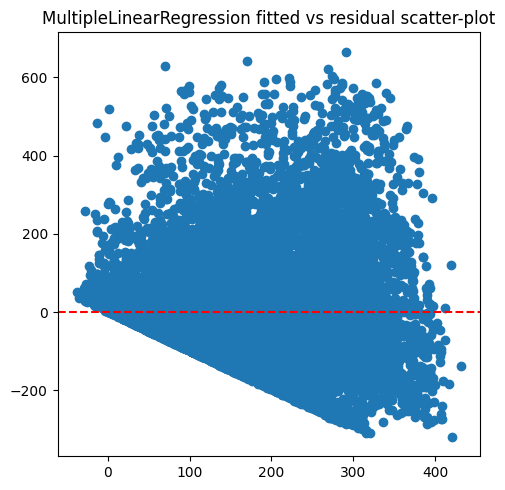

In [12]:
fit_residual_plot(mlr_model, X_train, y_train)

Condition Number: 154.10384248868058
Min Eigen Value:  0.02162819578974133
Learning Rate: 0.3000310762620823 Limit: 0.6000621525241646, Max Eigen value: 3.3329880772966427
Converged at epoch:  344


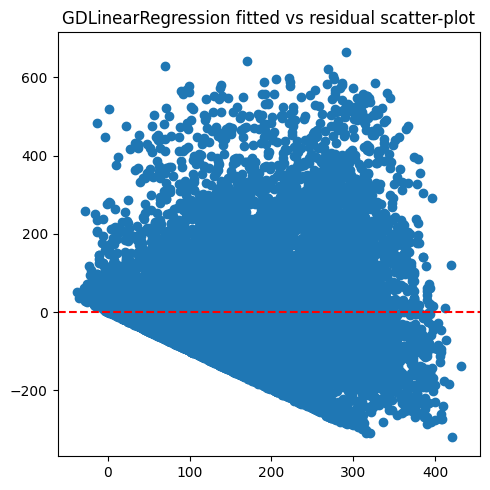

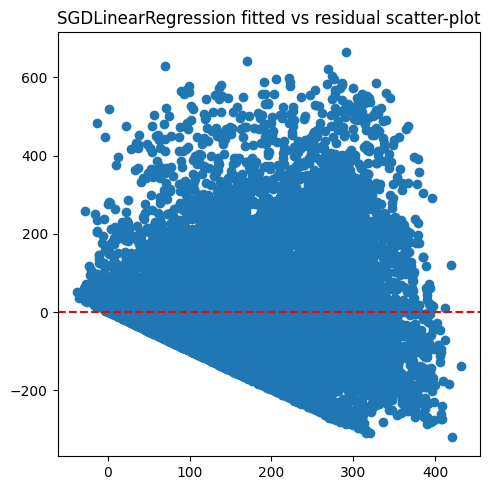

In [13]:
def gd_fit_residual_plot(model, X, y):
    model.fit_gd(X, y)
    X_plot = model._add_intercept(X)
    y_hat = X_plot @ model.beta_hat
    residual = model.residual(X, y)

    plt.figure(figsize=(5,5))
    plt.scatter(y_hat, residual)
    model_name = type(model).__name__
    plt.title(f"{model_name} fitted vs residual scatter-plot")
    plt.axhline(y=0, ls="--", color='red')
    plt.tight_layout()
    plt.show()


gd_fit_residual_plot(gd_mlr, X_train, y_train)


def sgd_fit_residual_plot(model, X, y):
    model.fit_sgd(X, y)
    X_plot = model._add_intercept(X)
    y_hat = X_plot @ model.beta_hat
    residual = model.residual(X, y)

    plt.figure(figsize=(5,5))
    plt.scatter(y_hat, residual)
    model_name = type(model).__name__
    plt.title(f"{model_name} fitted vs residual scatter-plot")
    plt.axhline(y=0, ls="--", color='red')
    plt.tight_layout()
    plt.show()

sgd_fit_residual_plot(sgd_mlr, X_train, y_train)

(13903,) (13903,)


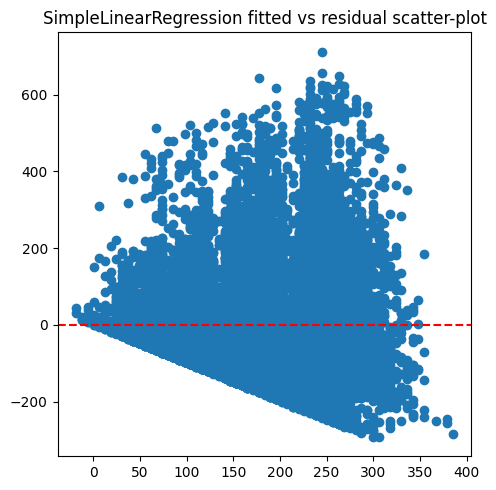

In [19]:
X_slr = df['atemp']
X_tr_slr, X_test_slr, _, _ = train_test_split(X_slr, y, test_size=0.2, shuffle=False)

slr_model.fit(X_tr_slr, y_train)

y_hat = slr_model.beta_0 + (slr_model.beta_1 * (X_tr_slr))

residual = slr_model.residual(X_tr_slr, y_train)

print(y_hat.shape, residual.shape)

plt.figure(figsize=(5,5))
plt.scatter(y_hat, residual)
model_name = type(slr_model).__name__
plt.title(f"{model_name} fitted vs residual scatter-plot")
plt.axhline(y=0, ls="--", color='red')
plt.tight_layout()
plt.show()
